In [1]:
import numpy as np

In [2]:
import pandas as pd

# Data Processing
patients = pd.read_csv("patients.csv")
diagnoses = pd.read_csv("diagnoses.csv")
outcomes = pd.read_csv("outcomes.csv")
labs = pd.read_csv("labs.csv")

In [3]:
patients = patients.merge(diagnoses, on ="DiagnosisID")
patients = patients.merge(outcomes, on = "OutcomeID")

In [4]:
patients["AdmissionDate"] = pd.to_datetime(patients["AdmissionDate"])
patients["DischargeDate"] = pd.to_datetime(patients["DischargeDate"])
patients["LengthOfStay"] = (patients["DischargeDate"] - patients["AdmissionDate"]).dt.days

In [15]:
patients["OutcomeEncoded"] = patients["OutcomeName"].map({
    "Recovered": 0,
    "Complicated": 1,
    "Deceased": 1
})

In [16]:
patients["HighRisk"] = np.where((patients['Age'] > 65) | (patients["OutcomeName"].isin(["Complications", "Deceased"])),1,0)

In [17]:
# Feature Engineering or dictionary 

abnormal_conditions = {
    'Blood Sugar': lambda x: x > 120,
    'Cholesterol': lambda x: x > 200,
    'Hemoglobin': lambda x: x < 13
}

def count_abnormal_labs(patient_id):
    patient_labs = labs[labs['PatientID'] == patient_id]
    count = 0
    for test_name, condition in abnormal_conditions.items():
        test_result = patient_labs[patient_labs['TestName'] == test_name]
        count += test_result['Result'].apply(condition).sum()
    return count
patients['AbnormalLabCount'] = patients['PatientID'].apply(count_abnormal_labs)

Model Training

In [37]:
features = patients[['Age', 'LengthOfStay','TreatmentCost']]
target = patients['OutcomeEncoded']


In [38]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    features, target, test_size=0.3, random_state=42
)

ML -
1. supervised - input + output - linear_Regression, Logistic Regression etc
2. unsupervised - input
3. reinforcement - rewards


In [39]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter = 500)
model.fit(x_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,500
,multi_class,'deprecated'


In [40]:
print(x_train.shape)
print(y_train.shape)

(140, 3)
(140,)


In [41]:
print(x_train.isnull().sum())
print(y_train.isnull().sum())

print("\nTarget values:")
print(y_train.unique())


Age              0
LengthOfStay     0
TreatmentCost    0
dtype: int64
0

Target values:
[1 0]


In [42]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
y_pred = model.predict(x_test)
print("Classfication Report:")
print(classification_report(y_test, y_pred))

Classfication Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        17
           1       0.72      1.00      0.83        43

    accuracy                           0.72        60
   macro avg       0.36      0.50      0.42        60
weighted avg       0.51      0.72      0.60        60



C:\Users\MOHIT\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\MOHIT\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\MOHIT\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

ROC Curve

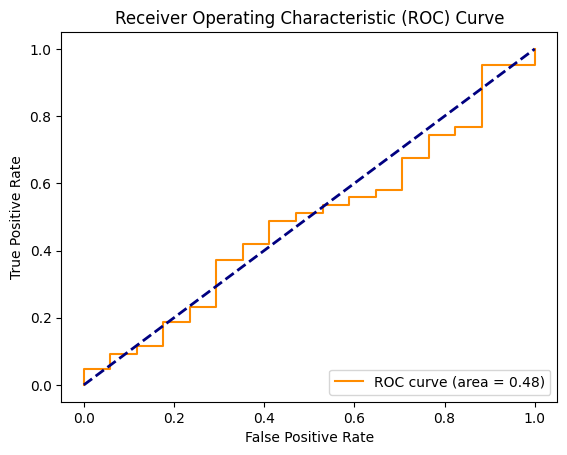

In [43]:
import matplotlib.pyplot as plt
from sklearn.metrics  import roc_curve, auc

y_prob = model.predict_proba(x_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [44]:
import joblib
joblib.dump(model, 'Risk_Model.ipynb')

['Risk_Model.ipynb']

Deploying Model, Risk Prediction App

In [45]:
pip install streamlit

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
import streamlit as st 
import pandas as pd
import joblib

model = joblib.load('risk_model.ipynb')

st.title("Healthcare Risk Statisfication App")

age = st.number_input("Age", min_value=0)
length_of_stay = st.number_input("Length of Stay (in days)", min_value=0.0)
treatment_cost = st.number_input("Treatment Cost", min_value=0.0)

if st.button("Predict"):
    input_data = pd.DataFrame([[age, length_of_stay, treatment_cost]], columns=['Age', 'LengthOfStay', 'TreatmentCost'])
    prediction = model.predict(input_data)[0]
    probability = model.predict_proba(input_data)[0][1]

    st.write(f"Risk Prediction: {'High Risk' if prediction == 1 else 'Low Risk'}")
    st.write(f"Risk Probability: {round(probability, 2)}")

2026-11-23 10:32:24.874 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 10:32:24.876 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 10:32:24.880 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 10:32:24.882 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 10:32:24.883 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 10:32:24.885 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 10:32:24.887 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 10:32:24.892 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar